# Testing Lipschitz Libraries

In this notebook we will test the Lipschitz libraries deel-lip and monotonicnetworks on a simple regression problem for amplitude estimation.

## Data processing

The data used for this part of the analysis is the same the tutorials for Modern ML for LHC, regression modules. The data describes a 
$$
gg \rightarrow \gamma \gamma g
$$
process. 

In [2]:
import os
import sys
import random
import numpy as np

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import tqdm

import monotonicnetworks as lmn

import matplotlib.pyplot as plt

# "Homemade" modules
from models import UnconstrainedModel, LipschitzModel
from train_eval import train, evaluate, predict


In [3]:
# Data loading 
trn_dat = np.load('/Users/emilbarkkvamme/Documents/Studier/Master og Prosjekt/Prosjekt/Tutorials/dlpp-data/tutorial-2-data/trn_dat.npy')
trn_amp = np.load("/Users/emilbarkkvamme/Documents/Studier/Master og Prosjekt/Prosjekt/Tutorials/dlpp-data/tutorial-2-data/trn_amp.npy")

val_dat = np.load("/Users/emilbarkkvamme/Documents/Studier/Master og Prosjekt/Prosjekt/Tutorials/dlpp-data/tutorial-2-data/val_dat.npy")
val_amp = np.load("/Users/emilbarkkvamme/Documents/Studier/Master og Prosjekt/Prosjekt/Tutorials/dlpp-data/tutorial-2-data/val_amp.npy")

tst_dat = np.load("/Users/emilbarkkvamme/Documents/Studier/Master og Prosjekt/Prosjekt/Tutorials/dlpp-data/tutorial-2-data/tst_dat.npy")
tst_amp = np.load("/Users/emilbarkkvamme/Documents/Studier/Master og Prosjekt/Prosjekt/Tutorials/dlpp-data/tutorial-2-data/tst_amp.npy")

In [4]:
print(f"train data shape: {trn_dat.shape}")
print(f"train amp  shape: {trn_amp.shape}")
print(f"test  data shape: {tst_dat.shape}")
print(f"test  amp  shape: {tst_amp.shape}")
print(f"val   data shape: {val_dat.shape}")
print(f"val   amp  shape: {val_amp.shape}")

train data shape: (30000, 5, 4)
train amp  shape: (30000,)
test  data shape: (30000, 5, 4)
test  amp  shape: (30000,)
val   data shape: (30000, 5, 4)
val   amp  shape: (30000,)


The data is organized with 30 000 samples, where each sample contain 5 particles, each with 4 kinematic features. The target is the amplitude of the process, described by a single number.

## Visualization of the data

In [5]:
# utility functions for the data visualization
def get_init_pz(events):
    # Initial particle z-momentum
    return events[:, 0, 3] + events[:, 1, 3]

def get_mass(fv):
    # Invariant mass of a 4-vector
    msq = np.round(fv[:, 0]**2 - fv[:, 1]**2 - fv[:, 2]**2 - fv[:, 3]**2, 5)
    if (msq < 0.).any():
       raise Exception("mass squared is less than zero")
    return np.sqrt(msq)
    #return msq

def get_pt(fv):
    # Transverse momentum of a four vector
    ptsq = np.round(fv[:, 1]**2 + fv[:, 2]**2, 5)
    return np.sqrt(ptsq)

def get_met():
    # Missing transverse energy of a vector
    return np.abs(np.sum(fv[:, :, 1]+fv[:, :, 2], axis=1))

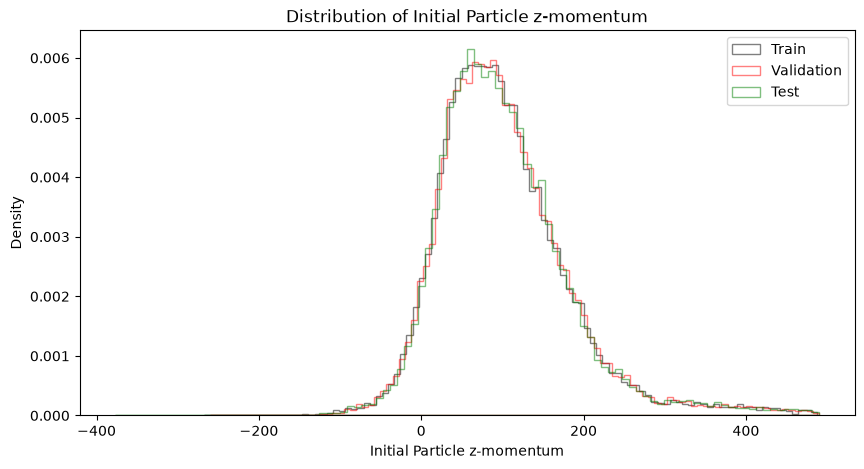

In [6]:
# Visualizing the initial pz distributions
train_pz = get_init_pz(trn_dat)
val_pz = get_init_pz(val_dat)
test_pz = get_init_pz(tst_dat)

plt.figure(figsize=(10, 5))
plt.hist(train_pz, bins=100, alpha=0.5, label='Train', density=True, histtype='stepfilled', fill=None)
plt.hist(val_pz, bins=100, alpha=0.5, label='Validation', density=True, histtype='stepfilled', fill=None, edgecolor='red')
plt.hist(test_pz, bins=100, alpha=0.5, label='Test', density=True, histtype='stepfilled', fill=None, edgecolor='green')
plt.xlabel('Initial Particle z-momentum')
plt.ylabel('Density')
plt.title('Distribution of Initial Particle z-momentum')
plt.legend()

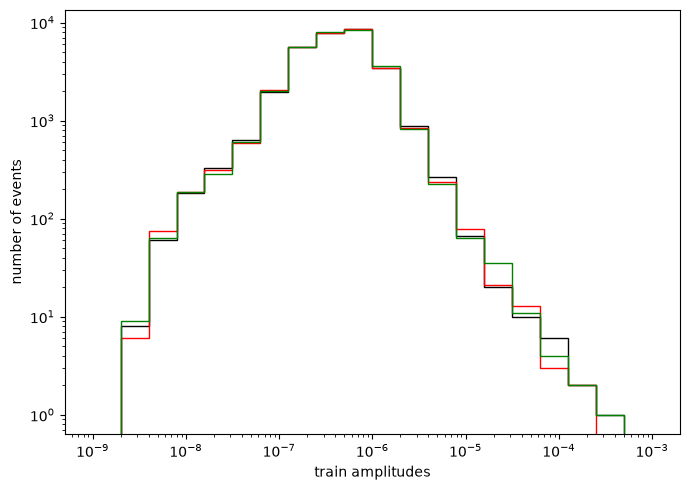

In [7]:
# Amplitudes
fig, axs = plt.subplots(1, 1, figsize=(7,5))
bins=np.logspace(-9, -3, 21)

axs.hist(trn_amp, histtype='stepfilled', fill=None, bins=bins)
axs.hist(val_amp, histtype='stepfilled', fill=None, bins=bins, edgecolor='red')
axs.hist(tst_amp, histtype='stepfilled', fill=None, bins=bins, edgecolor='green')

axs.set_yscale('log')
axs.set_xscale('log')

axs.set_xlabel("train amplitudes")
axs.set_ylabel("number of events")

fig.tight_layout()


We have verified that the data is likely distributed the same for the different datasets. This is important for training and validation. Next step is to scale the data to make it easier for the neural network to learn and to make the bounds for the Lipschitz constant easier to handle.

## Preprocessing

First, we flatten the data. We want the neural network to take as input a vector of length 20, corresponding to the 5 particles, each with 4 kinematic features. At this point we do not care about Lorentz invariance or permutation invariance.

In [8]:
# Flattening all particle kinematics into a single event vector
trn_data_flat = trn_dat.reshape(trn_dat.shape[0], -1)
val_data_flat = val_dat.reshape(val_dat.shape[0], -1)
tst_data_flat = tst_dat.reshape(tst_dat.shape[0], -1)

In [9]:
print(f"train data shape: {trn_data_flat.shape}")
print(f"validation data shape: {val_data_flat.shape}")
print(f"test data shape: {tst_data_flat.shape}")

train data shape: (30000, 20)
validation data shape: (30000, 20)
test data shape: (30000, 20)


In [10]:
# Standardize using sklean's StandardScaler
from sklearn.preprocessing import StandardScaler

# Scaling the kinematics
scaler = StandardScaler().fit(trn_data_flat)

trn_data_scaled = scaler.transform(trn_data_flat)
val_data_scaled = scaler.transform(val_data_flat)
tst_data_scaled = scaler.transform(tst_data_flat)

# Scaling the amplitudes -> The standard scaler leaves the large outliers, which is not ideal here


# Other possibility is logscaling
trn_amp_log_scaled = np.log(trn_amp.reshape(-1, 1))
val_amp_log_scaled = np.log(val_amp.reshape(-1, 1))
tst_amp_log_scaled = np.log(tst_amp.reshape(-1, 1))


amp_scaler = StandardScaler().fit(trn_amp_log_scaled)  # Fit the scaler on the log-scaled amplitudes
trn_amp_scaled = amp_scaler.transform(trn_amp_log_scaled)
val_amp_scaled = amp_scaler.transform(val_amp_log_scaled)
tst_amp_scaled = amp_scaler.transform(tst_amp_log_scaled)

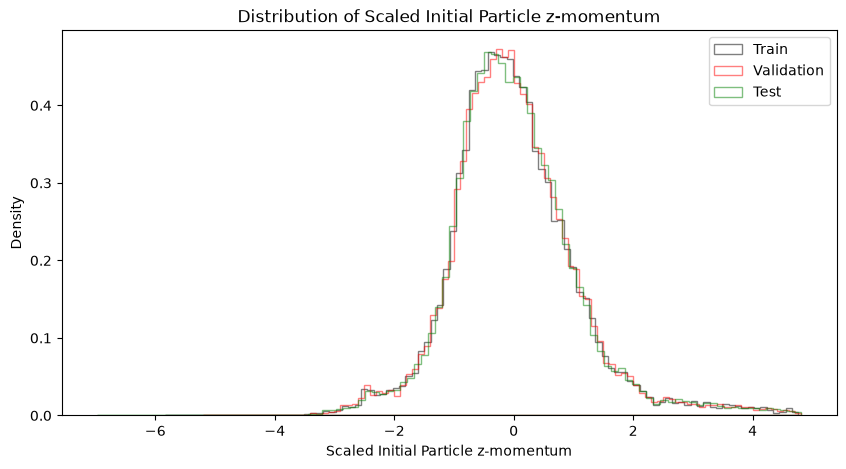

In [11]:
# Plotting the pz of the first two gluons after scaling
def get_scaled_pz(events_scaled):
    # Get the scaled z-momentum of the first two particles
    #print(f"Scaled events shape: {events_scaled.shape}")
    reshaped = events_scaled.reshape(events_scaled.shape[0], 5, 4)
    #print(f"Reshaped events shape: {reshaped.shape}")
    return reshaped[:, 0, 3] + reshaped[:, 1, 3]

train_scaled_pz = get_scaled_pz(trn_data_scaled)
val_scaled_pz = get_scaled_pz(val_data_scaled)
test_scaled_pz = get_scaled_pz(tst_data_scaled)

plt.figure(figsize=(10, 5))
plt.hist(train_scaled_pz, bins=100, alpha=0.5, label='Train', density=True, histtype='stepfilled', fill=None)
plt.hist(val_scaled_pz, bins=100, alpha=0.5, label='Validation', density=True, histtype='stepfilled', fill=None, edgecolor='red')
plt.hist(test_scaled_pz, bins=100, alpha=0.5, label='Test', density=True, histtype='stepfilled', fill=None, edgecolor='green')
plt.xlabel('Scaled Initial Particle z-momentum')
plt.ylabel('Density')
plt.title('Distribution of Scaled Initial Particle z-momentum')
plt.legend()
plt.show()

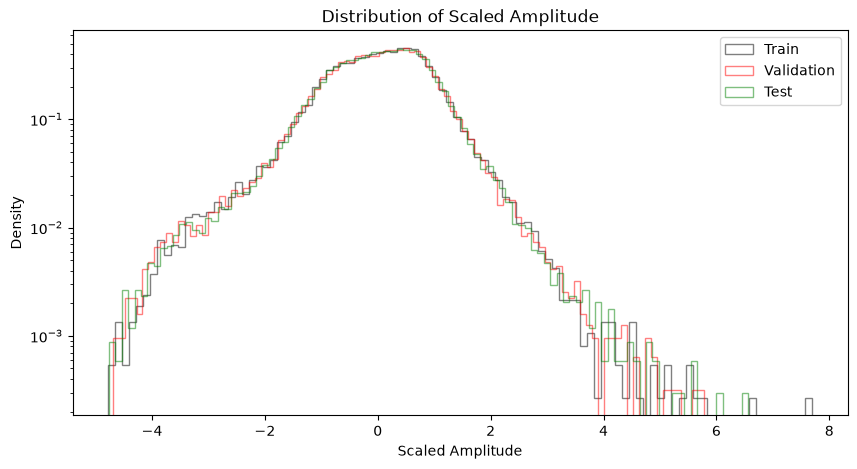

In [12]:
# Checking scaled amplitudes
plt.figure(figsize=(10, 5))
plt.hist(trn_amp_scaled, bins=100, alpha=0.5, label='Train', density=True, histtype='stepfilled', fill=None)
plt.hist(val_amp_scaled, bins=100, alpha=0.5, label='Validation', density=True, histtype='stepfilled', fill=None, edgecolor='red')
plt.hist(tst_amp_scaled, bins=100, alpha=0.5, label='Test', density=True, histtype='stepfilled', fill=None, edgecolor='green')
plt.xlabel('Scaled Amplitude')
plt.ylabel('Density')
plt.yscale('log')
plt.title('Distribution of Scaled Amplitude')
plt.legend()
plt.show()

## Constructing the dataset objects

In [13]:
class amp_dataset(Dataset):
    def __init__(self, data, amplitudes):
        self.data = torch.tensor(data, dtype=torch.float32)
        self.amplitudes = torch.tensor(amplitudes, dtype=torch.float32)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx], self.amplitudes[idx]

In [14]:
# Preparing the dataset objects
trn_dataset = amp_dataset(trn_data_scaled, trn_amp_log_scaled)
val_dataset = amp_dataset(val_data_scaled, val_amp_log_scaled)
test_dataset = amp_dataset(tst_data_scaled, tst_amp_log_scaled)

# Preparing the dataloaders
SEED = 42 # Setting seeds for reproducibility
BATCH_SIZE = 64
random.seed(SEED)
torch.manual_seed(SEED)

generator = torch.Generator() # Setting the seeded RNG for the dataloaders
generator.manual_seed(SEED)

trn_loader = DataLoader(trn_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=generator)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, generator=generator)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, generator=generator)

In [15]:
print("Training dataset length:", len(trn_dataset))
print("Validation dataset length:", len(val_dataset))
print("Test dataset length:", len(test_dataset))

X_train, y_train = next(iter(trn_loader))
print("Shape of a batch of training data:", X_train.shape)
print("Shape of a batch of training amplitudes:", y_train.shape)
print("First batch of training data:", X_train)

Training dataset length: 30000
Validation dataset length: 30000
Test dataset length: 30000
Shape of a batch of training data: torch.Size([64, 20])
Shape of a batch of training amplitudes: torch.Size([64, 1])
First batch of training data: tensor([[ 0.4493, -0.0058, -0.0058,  ...,  0.2075, -0.4071,  0.4235],
        [ 2.6225, -0.0058, -0.0058,  ...,  1.5080,  1.2574,  0.9323],
        [-0.3639, -0.0058, -0.0058,  ...,  1.8867, -0.2163, -0.0900],
        ...,
        [-1.3239, -0.0058, -0.0058,  ..., -0.5316, -0.3449, -0.4189],
        [-0.2828, -0.0058, -0.0058,  ..., -0.2261, -0.6096,  0.8008],
        [-0.9081, -0.0058, -0.0058,  ..., -0.4744,  0.2549,  0.0041]])


In [16]:
class UnconstrainedModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, depth = 3):
        super(UnconstrainedModel, self).__init__()

        if depth < 2: # Check for valid depth
            raise ValueError("Depth must be at least 2 for the UnconstrainedModel.")

        layers = [ # Adding input layer
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU()
        ]

        for _ in range(depth - 2): # Add hidden layers according to depth
            layers.append(nn.Linear(hidden_dim, hidden_dim))
            layers.append(nn.ReLU())

        layers.append(nn.Linear(hidden_dim, output_dim)) # Output layer

        self.layers = nn.Sequential(*layers) # Create the sequential model with the defined layers
        
    def forward(self, x):
        return self.layers(x)


class LipschitzModel(nn.Module):
    def __init__(self, 
                 input_dim, 
                 hidden_dim, 
                 output_dim, 
                 n_groups=2,
                 depth = 3, 
                 lipschitz_bound=1.0):
        super(LipschitzModel, self).__init__()

        ######## CHECKING PARAMETERS #######
        if hidden_dim % n_groups != 0: # Check for divisibility for the GroupSort activation
            raise ValueError(f"hidden_dim ({hidden_dim}) must be divisible by n_groups ({n_groups})")
        
        if depth < 2: # Check for valid depth
            raise ValueError("Depth must be at least 2 for the LipschitzModel.")

        ####### ADDING LAYERS #######
        layers = [ # Adding input layer with direct normalization
            lmn.direct_norm(torch.nn.Linear(input_dim, hidden_dim), kind="one-inf"),
            lmn.GroupSort(n_groups)
        ]

        for _ in range(depth - 2): # Add hidden layers according to depth
            layers.append(lmn.direct_norm(nn.Linear(hidden_dim, hidden_dim), kind="inf"))
            layers.append(lmn.GroupSort(n_groups))

        layers.append(lmn.direct_norm(nn.Linear(hidden_dim, output_dim), kind="inf")) # Output layer

        self.layers = nn.Sequential(*layers) # Create the sequential model with the defined layers
        self.lipschitz_bound = lipschitz_bound  # Store the Lipschitz bound for later use
        
    def forward(self, x):
        return self.layers(x)*self.lipschitz_bound  

## Model Training

In [17]:
device = "cuda" if torch.cuda.is_available() else "cpu" # To utilise the best available computing resources

LEARNING_RATE = 0.001
HIDDEN_DIM = 64

# Lipschitz Models
Lipschitz_1_model = LipschitzModel(input_dim=trn_data_scaled.shape[1], hidden_dim=HIDDEN_DIM, output_dim=1, lipschitz_bound=1.0).to(device)
Lipschitz_2_model = LipschitzModel(input_dim=trn_data_scaled.shape[1], hidden_dim=HIDDEN_DIM, output_dim=1, lipschitz_bound=2.0).to(device)
Lipschitz_5_model = LipschitzModel(input_dim=trn_data_scaled.shape[1], hidden_dim=HIDDEN_DIM, output_dim=1, lipschitz_bound=5.0).to(device)

#Unconstrained model
Unconstrained_model = UnconstrainedModel(input_dim=trn_data_scaled.shape[1], hidden_dim=HIDDEN_DIM, output_dim=1).to(device)

# Optimizers and loss functions
optimizer_Lipschitz_1 = torch.optim.Adam(Lipschitz_1_model.parameters(), lr=LEARNING_RATE)
optimizer_Lipschitz_2 = torch.optim.Adam(Lipschitz_2_model.parameters(), lr=LEARNING_RATE)
optimizer_Lipschitz_5 = torch.optim.Adam(Lipschitz_5_model.parameters(), lr=LEARNING_RATE)
optimizer_Unconstrained = torch.optim.Adam(Unconstrained_model.parameters(), lr=LEARNING_RATE)

loss_fn = nn.MSELoss()



In [17]:
# Training
NUM_EPOCHS = 15
train_losses_L1, val_losses_L1 = train(model =Lipschitz_1_model,
    train_loader = trn_loader,
    val_loader = val_loader,
    optimizer = optimizer_Lipschitz_1,
    loss_fn = loss_fn,
    num_epochs = NUM_EPOCHS,
    device = device)

train_losses_L2, val_losses_L2 = train(model =Lipschitz_2_model,
    train_loader = trn_loader,
    val_loader = val_loader,
    optimizer = optimizer_Lipschitz_2,
    loss_fn = loss_fn,
    num_epochs = NUM_EPOCHS,
    device = device)

train_losses_L5, val_losses_L5 = train(model =Lipschitz_5_model,
    train_loader = trn_loader,
    val_loader = val_loader,
    optimizer = optimizer_Lipschitz_5,
    loss_fn = loss_fn,
    num_epochs = NUM_EPOCHS,
    device = device)

train_losses_Unconstrained, val_losses_Unconstrained = train(model =Unconstrained_model,
    train_loader = trn_loader,
    val_loader = val_loader,
    optimizer = optimizer_Unconstrained,
    loss_fn = loss_fn,
    num_epochs = NUM_EPOCHS,
    device = device)



Epoch 1
-------------------------------
Epoch 2
-------------------------------
Epoch 3
-------------------------------
Epoch 4
-------------------------------
Epoch 5
-------------------------------
Epoch 6
-------------------------------
Epoch 7
-------------------------------
Epoch 8
-------------------------------
Epoch 9
-------------------------------
Epoch 10
-------------------------------
Epoch 11
-------------------------------
Epoch 12
-------------------------------
Epoch 13
-------------------------------
Epoch 14
-------------------------------
Epoch 15
-------------------------------
Epoch 1
-------------------------------
Epoch 2
-------------------------------
Epoch 3
-------------------------------
Epoch 4
-------------------------------
Epoch 5
-------------------------------
Epoch 6
-------------------------------
Epoch 7
-------------------------------
Epoch 8
-------------------------------
Epoch 9
-------------------------------
Epoch 10
-------------------------

## Performance evaluation

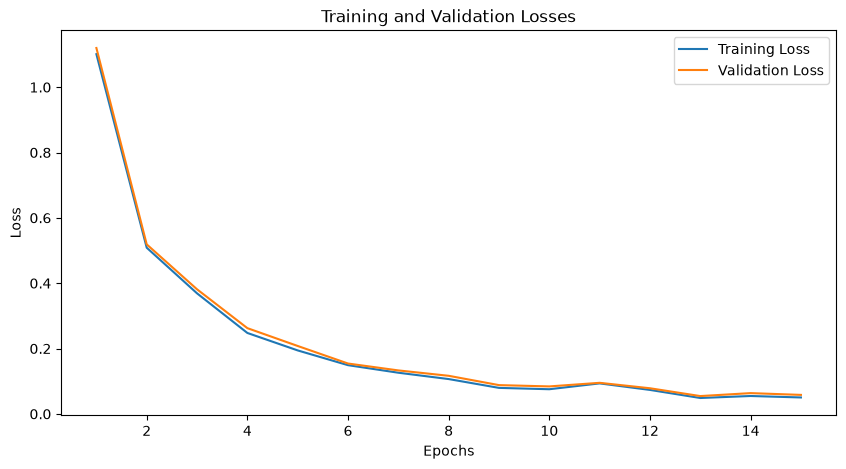

In [18]:
# Plotting the training and validation losses
plt.figure(figsize=(10, 5))
plt.plot(range(1, NUM_EPOCHS + 1), train_losses_Unconstrained, label='Training Loss')
plt.plot(range(1, NUM_EPOCHS + 1), val_losses_Unconstrained, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Losses')
plt.legend()

In [19]:
L1_predictions = predict(Lipschitz_1_model, test_loader, device=device)
L2_predictions = predict(Lipschitz_2_model, test_loader, device=device)
L5_predictions = predict(Lipschitz_5_model, test_loader, device=device)
Unconstrained_predictions = predict(Unconstrained_model, test_loader, device=device)

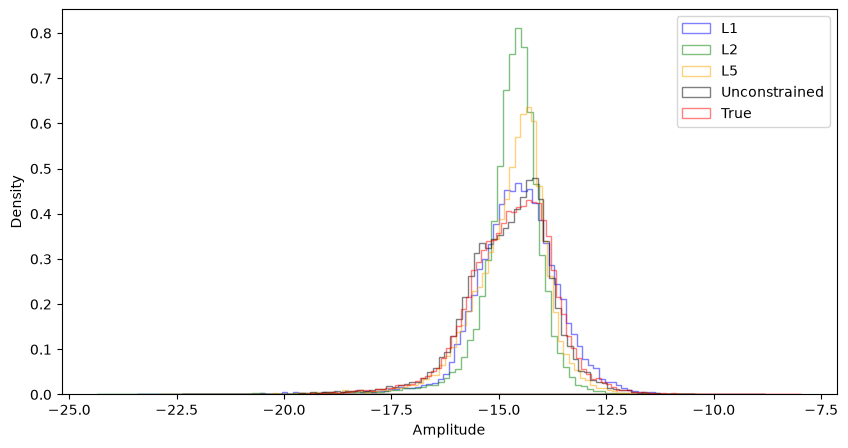

In [20]:
# Plotting the predicted vs true amplitudes for the Lipschitz model
plt.figure(figsize=(10, 5))
plt.hist(L1_predictions, bins=100, alpha=0.5, label='L1', density=True, histtype='stepfilled', fill=None, edgecolor='blue')
plt.hist(L2_predictions, bins=100, alpha=0.5, label='L2', density=True, histtype='stepfilled', fill=None, edgecolor='green')
plt.hist(L5_predictions, bins=100, alpha=0.5, label='L5', density=True, histtype='stepfilled', fill=None, edgecolor='orange')
plt.hist(Unconstrained_predictions, bins=100, alpha=0.5, label='Unconstrained', density=True, histtype='stepfilled', fill=None, edgecolor='black')
plt.hist(tst_amp_log_scaled, bins=100, alpha=0.5, label='True', density=True, histtype='stepfilled', fill=None, edgecolor='red')
plt.xlabel('Amplitude')
plt.ylabel('Density')
#plt.title('Predicted vs True Amplitudes for Lipschitz Model')
plt.legend()
plt.savefig('Plots/Initial_lipNN_test.pdf')

plt.show()

In [1]:
# Plotting the error distributions for the Lipschitz model
L1_errors = L1_predictions - tst_amp_log_scaled.flatten()
L2_errors = L2_predictions - tst_amp_log_scaled.flatten()
L5_errors = L5_predictions - tst_amp_log_scaled.flatten()

plt.figure(figsize=(10, 5))
plt.hist(L1_errors, bins=100, alpha=0.5, label='L1', density=True, histtype='stepfilled', fill=None, edgecolor='blue')
plt.hist(L2_errors, bins=100, alpha=0.5, label='L2', density=True, histtype='stepfilled', fill=None, edgecolor='green')
plt.hist(L5_errors, bins=100, alpha=0.5, label='L5', density=True, histtype='stepfilled', fill=None, edgecolor='orange')
plt.hist(Unconstrained_predictions - tst_amp_log_scaled.flatten(), bins=100, alpha=0.5, label='Unconstrained', density=True, histtype='stepfilled', fill=None, edgecolor='black')
plt.xlabel('Error (Predicted - True)')
plt.ylabel('Density')
#plt.title('Error Distributions for Lipschitz Model')
plt.legend()
#plt.savefig('Plots/Initial_lipNN_error_test.pdf')
plt.show()

NameError: name 'L1_predictions' is not defined

We can see that under the same conditions (similar architecture, same optimizer,learning rate, number of epochs, etc.) the unconstrained model performs significantly better than the Lipschitz consstrained model. This could be due to the fact that the Lipschitz constraint is a very strict constraint and reduces the expressivity of the model. by experience, the preprocessing is very important for the outcome of the Lipschitz model.

In order to increase the performance of the Lipschitz model, we can try to increase the Lipschitz constant. This allows for more expressivity of the model, but trades of robustness.

We can approach this even more systematically by testing a finer grid of Lipschitz constants and evaluating the MSE dependence on the Lipschitz constant.


In [23]:
print(np.zeros((3, 4)))

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


In [ ]:
L_arr = np.arange(1, 6, 0.5)  # Array of Lipschitz constants from 0.1 to 5.0
HIDDEN_DIM = 24  # Hidden dimension for the Lipschitz model
NUM_EPOCHS = 100 # Number of epochs for training
N_GROUPS = 4  # Number of groups for the GroupSort activation
MAX_ITER = 100
REPEATS = 5  # Number of times to repeat the training for each Lipschitz constant
device = "cuda" if torch.cuda.is_available() else "cpu" # To utilise the best available computing resources
loss_fn = nn.MSELoss()

MSE_loss_arr = np.zeros((len(L_arr), REPEATS))  # Array to store MSE losses for each Lipschitz constant and repeat
std_loss_arr = np.zeros((len(L_arr), REPEATS))  # Array to store standard deviation of losses for each Lipschitz constant

np.random.seed(42)  # Set a seed for reproducibility of the random seeds
seeds = np.random.randint(0, 10000, size=REPEATS)  # Generate random seeds for each repeat

for i, L in enumerate(L_arr):
    for j in range(REPEATS):
        print(f"Training Lipschitz model with L={L}, iteration {i+1}/3")
        torch.manual_seed(seeds[j])  # Set the seed for reproducibility
        # Create a Lipschitz model with the specified Lipschitz constant
        model = LipschitzModel(input_dim=trn_data_scaled.shape[1], hidden_dim=HIDDEN_DIM, output_dim=1, lipschitz_bound=L).to(device)
        
        # Create an optimizer for the model
        optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
        
        # Train the model
        train_losses, val_losses = train(model, trn_loader, val_loader, optimizer, loss_fn, NUM_EPOCHS, MAX_ITER, device=device)
        
        # Evaluate the model on the test set
        test_predictions = predict(model, test_loader, device=device)
        
        # Store the MSE loss for this Lipschitz constant
        mse_loss = loss_fn(torch.tensor(test_predictions), torch.tensor(tst_amp_log_scaled)).item()
        MSE_loss_arr[i, j] += mse_loss  # Accumulate the MSE loss for averaging later

        std_loss = np.std(test_predictions - tst_amp_log_scaled)
        std_loss_arr[i, j] += std_loss  # Accumulate the standard deviation for averaging later


Epoch 88
-------------------------------
Epoch 89
-------------------------------
Epoch 90
-------------------------------
Epoch 91
-------------------------------
Epoch 92
-------------------------------
Epoch 93
-------------------------------
Epoch 94
-------------------------------
Epoch 95
-------------------------------
Epoch 96
-------------------------------
Epoch 97
-------------------------------
Epoch 98
-------------------------------
Epoch 99
-------------------------------
Epoch 100
-------------------------------
Training Lipschitz model with L=1.0, iteration 1/3
Epoch 1
-------------------------------
Epoch 2
-------------------------------
Epoch 3
-------------------------------
Epoch 4
-------------------------------
Epoch 5
-------------------------------
Epoch 6
-------------------------------
Epoch 7
-------------------------------
Epoch 8
-------------------------------
Epoch 9
-------------------------------
Epoch 10
-------------------------------
Epoch 11
-----

In [32]:
# Average the losses over the repeats
MSE_loss_arr_converged = np.mean(MSE_loss_arr, axis=1)
std_MSE_loss_arr_converged = np.std(MSE_loss_arr, axis=1)
print("MSE Losses for each Lipschitz constant:", MSE_loss_arr_converged)

MSE Losses for each Lipschitz constant: [0.25891638 0.11359159 0.09444448 0.05878478 0.05410261 0.04804564
 0.06395098 0.03674286 0.03802767 0.03193944]


In [52]:
# Training an unconstrained as a baseline
HIDDEN_DIM = 64  # Hidden dimension for the Lipschitz model
NUM_EPOCHS = 50 # Number of epochs for training
loss_fn = nn.MSELoss()

Unconstrained_model = UnconstrainedModel(input_dim=trn_data_scaled.shape[1], hidden_dim=HIDDEN_DIM, output_dim=1).to(device)

train_losses, val_losses = train(Unconstrained_model, trn_loader, val_loader, optimizer_Unconstrained, loss_fn, NUM_EPOCHS)

preds = predict(Unconstrained_model, test_loader)

unconstrained_loss = loss_fn(torch.tensor(preds), torch.tensor(tst_amp_log_scaled)).item()


Epoch 1
-------------------------------
Epoch 2
-------------------------------
Epoch 3
-------------------------------
Epoch 4
-------------------------------
Epoch 5
-------------------------------
Epoch 6
-------------------------------
Epoch 7
-------------------------------
Epoch 8
-------------------------------
Epoch 9
-------------------------------
Epoch 10
-------------------------------
Epoch 11
-------------------------------
Epoch 12
-------------------------------
Epoch 13
-------------------------------
Epoch 14
-------------------------------
Epoch 15
-------------------------------
Epoch 16
-------------------------------
Epoch 17
-------------------------------
Epoch 18
-------------------------------
Epoch 19
-------------------------------
Epoch 20
-------------------------------
Epoch 21
-------------------------------
Epoch 22
-------------------------------
Epoch 23
-------------------------------
Epoch 24
-------------------------------
Epoch 25
----------------

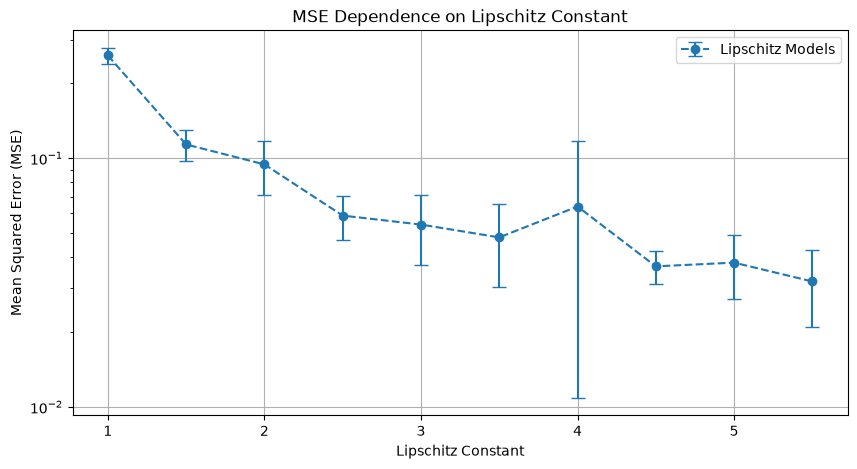

In [35]:
# Plotting the loss dependence on the Lipschitz constant, with errorbars representing the standard deviation of the loss
plt.figure(figsize=(10, 5))
#plt.plot(L_arr, MSE_loss_arr, marker='o', label='MSE loss')
plt.errorbar(L_arr, MSE_loss_arr_converged, yerr=std_MSE_loss_arr_converged, fmt='o--', capsize=5, label='Lipschitz Models')
#plt.axhline(y=unconstrained_loss, color='r', linestyle='--', label='Unconstrained Model')
plt.xlabel('Lipschitz Constant')
plt.ylabel('Mean Squared Error (MSE)')
plt.yscale('log')
plt.legend()
plt.grid(True)
plt.savefig('Plots/MSE_dependence_on_Lipschitz_constant.pdf')


plt.title('MSE Dependence on Lipschitz Constant')
plt.show()

## Testing different architectural features
For further testing and insight into the capabilities we want to test different architectural features. We will test the following:
- Different depths
- Different widths
- Different data sizes
- Different Lipschitz constants

### Networks Depths
Using four different depths for testing we evaluate the performance of the Lipschitz constrained model. The depths are 3, 4, 6 and 8 layers. The width is kept constant at 64 neurons per layer. The Lipschitz constant is set to 1.0.

In [23]:
depths = [3, 4, 6, 8, 14]
predictions_dict_depth = {}  # Dictionary to store predictions for each depth
LEARNING_RATE = 0.001
HIDDEN_DIM = 64
NUM_EPOCHS = 50
loss_fn = nn.MSELoss()
device = "cuda" if torch.cuda.is_available() else "cpu" # To utilise the best available computing resources

for depth in depths:
    # Create a Lipschitz model with the specified depth
    model = LipschitzModel(input_dim=trn_data_scaled.shape[1], hidden_dim=HIDDEN_DIM, output_dim=1, lipschitz_bound=1.0, depth=depth).to(device)
    
    # Create an optimizer for the model
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    
    # Train the model
    train_losses, val_losses = train(model=model,
                                     train_loader=trn_loader,
                                     val_loader=val_loader,
                                     optimizer=optimizer,
                                     loss_fn=loss_fn,
                                     num_epochs=NUM_EPOCHS)
    
    # Evaluate the model on the test set
    test_predictions = predict(model, test_loader)
    predictions_dict_depth[depth] = test_predictions

Epoch 1
-------------------------------
Epoch 2
-------------------------------
Epoch 3
-------------------------------
Epoch 4
-------------------------------
Epoch 5
-------------------------------
Epoch 6
-------------------------------
Epoch 7
-------------------------------
Epoch 8
-------------------------------
Epoch 9
-------------------------------
Epoch 10
-------------------------------
Epoch 11
-------------------------------
Epoch 12
-------------------------------
Epoch 13
-------------------------------
Epoch 14
-------------------------------
Epoch 15
-------------------------------
Epoch 16
-------------------------------
Epoch 17
-------------------------------
Epoch 18
-------------------------------
Epoch 19
-------------------------------
Epoch 20
-------------------------------
Epoch 21
-------------------------------
Epoch 22
-------------------------------
Epoch 23
-------------------------------
Epoch 24
-------------------------------
Epoch 25
----------------

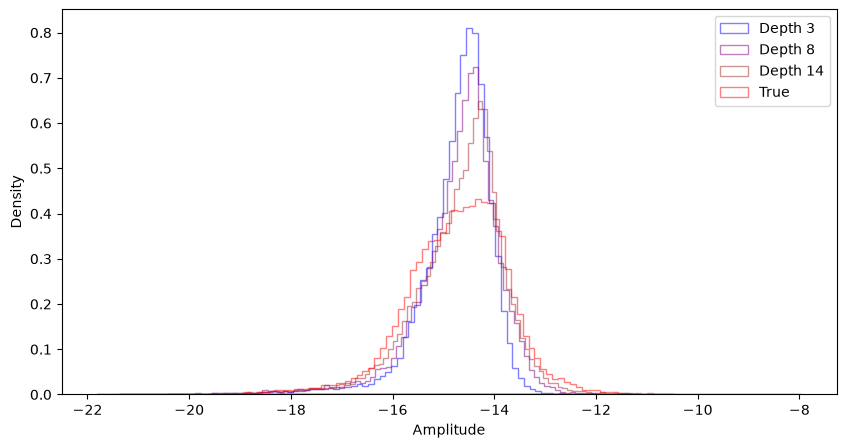

In [27]:
# Plotting
colors = ['blue', 'green', 'orange', 'purple', 'brown']  # Define colors for each depth
plt.figure(figsize=(10, 5))
for depth, predictions in predictions_dict_depth.items():
    if depth == 4 or depth == 6:  # Only plot for depths 4 and 6
        continue  # Skip plotting for depths 4 and 6
    plt.hist(predictions, bins=100, alpha=0.5, label=f'Depth {depth}', density=True, histtype='stepfilled', fill=None, edgecolor=colors[depths.index(depth)])
plt.hist(tst_amp_log_scaled, bins=100, alpha=0.5, label='True', density=True, histtype='stepfilled', fill=None, edgecolor='red')
plt.xlabel('Amplitude')
plt.ylabel('Density')
plt.legend()
plt.savefig('Plots/Depths_lipNN_test.pdf')

plt.show()

In [28]:
# Test with a very deep model
depth = 20
model = LipschitzModel(input_dim=trn_data_scaled.shape[1], hidden_dim=HIDDEN_DIM, output_dim=1, lipschitz_bound=1.0, depth=depth).to(device)

train_losses, val_losses = train(model=model,
                                 train_loader=trn_loader,
                                 val_loader=val_loader,
                                 optimizer=torch.optim.Adam(model.parameters(), lr=LEARNING_RATE),
                                 loss_fn=loss_fn,
                                 num_epochs=NUM_EPOCHS)

deep_predictions = predict(model, test_loader)

Epoch 1
-------------------------------
Epoch 2
-------------------------------
Epoch 3
-------------------------------
Epoch 4
-------------------------------
Epoch 5
-------------------------------
Epoch 6
-------------------------------
Epoch 7
-------------------------------
Epoch 8
-------------------------------
Epoch 9
-------------------------------
Epoch 10
-------------------------------
Epoch 11
-------------------------------
Epoch 12
-------------------------------
Epoch 13
-------------------------------
Epoch 14
-------------------------------
Epoch 15
-------------------------------
Epoch 16
-------------------------------
Epoch 17
-------------------------------
Epoch 18
-------------------------------
Epoch 19
-------------------------------
Epoch 20
-------------------------------
Epoch 21
-------------------------------
Epoch 22
-------------------------------
Epoch 23
-------------------------------
Epoch 24
-------------------------------
Epoch 25
----------------

In [31]:
# adding to the pred dictionary
predictions_dict_depth[depth] = deep_predictions

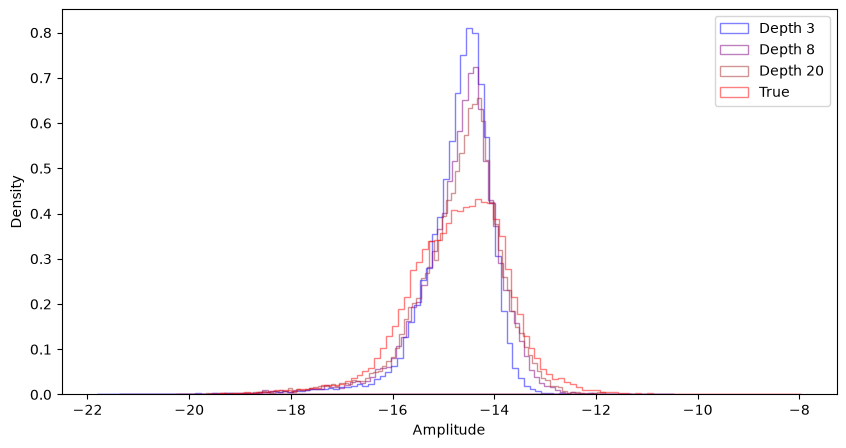

In [39]:
# Plotting specific depths
chosen_depths = [3, 8, 20]  # Include the very deep model, and the shallowest
colors = ['blue', 'green', 'orange', 'purple', 'brown']  # Define colors for each depth

plt.figure(figsize=(10, 5))
for depth in chosen_depths:
    predictions = predictions_dict_depth[depth]
    plt.hist(predictions, bins=100, alpha=0.5, label=f'Depth {depth}', density=True, histtype='stepfilled', fill=None, edgecolor=colors[depths.index(depth) if depth in depths else -1])
plt.hist(tst_amp_log_scaled, bins=100, alpha=0.5, label='True', density=True, histtype='stepfilled', fill=None, edgecolor='red')
plt.xlabel('Amplitude')
plt.ylabel('Density')
plt.legend()
plt.savefig('Plots/Chosen_Depths_lipNN_test.pdf')
plt.show()

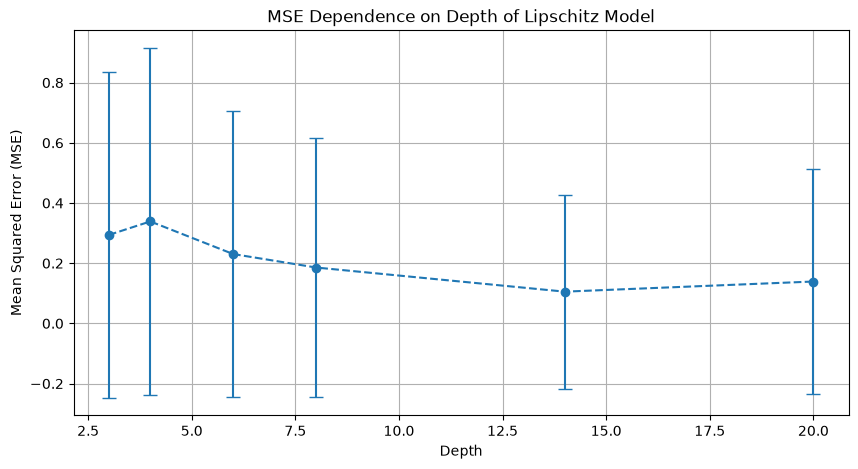

In [38]:
# Calculating and plotting the errors for the chosen depths
errors_dict = {}
all_depths = predictions_dict_depth.keys()  # Get all depths including the very deep model
std_errors_dict = {}
for depth in all_depths:
    predictions = predictions_dict_depth[depth]
    errors = nn.MSELoss()(torch.tensor(predictions), torch.tensor(tst_amp_log_scaled)).item()
    std_error = np.std(predictions - tst_amp_log_scaled)
    errors_dict[depth] = errors
    std_errors_dict[depth] = std_error

# Plotting the errors for all depths
plt.figure(figsize=(10, 5))

plt.errorbar(list(errors_dict.keys()), list(errors_dict.values()), yerr=list(std_errors_dict.values()), fmt='o--', capsize=5, label='MSE with Std Dev')
plt.xlabel('Depth')
plt.ylabel('Mean Squared Error (MSE)')

plt.grid(True)
plt.savefig('Plots/MSE_dependence_on_depth.pdf')
plt.title('MSE Dependence on Depth of Lipschitz Model')

plt.show()

### Network widths
Using four different widths for testing we evaluate the performance of the Lipschitz constrained model. The widths are 32, 64, 128 and 256 neurons per layer. The depth is kept constant at 3 layers. The Lipschitz constant is set to 1.0.

In [ ]:
depth = 3
widths = [32, 64, 128, 256]
predictions_dict_width = {}  # Dictionary to store predictions for each depth
LEARNING_RATE = 0.001
NUM_EPOCHS = 100
loss_fn = nn.MSELoss()

for width in widths:
    # Create a Lipschitz model with the specified depth
    hidden_dim = width  # Set the hidden dimension to the current width
    model = LipschitzModel(input_dim=trn_data_scaled.shape[1], hidden_dim=hidden_dim, output_dim=1, lipschitz_bound=1.0, depth=depth).to(device)
    
    # Create an optimizer for the model
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    
    # Train the model
    train_losses, val_losses = train(model=model,
                                     train_loader=trn_loader,
                                     val_loader=val_loader,
                                     optimizer=optimizer,
                                     loss_fn=loss_fn,
                                     num_epochs=NUM_EPOCHS)
    
    # Evaluate the model on the test set
    test_predictions = predict(model, test_loader)
    predictions_dict[width] = test_predictions

Epoch 1
-------------------------------
Epoch 2
-------------------------------
Epoch 3
-------------------------------
Epoch 4
-------------------------------
Epoch 5
-------------------------------
Epoch 6
-------------------------------
Epoch 7
-------------------------------
Epoch 8
-------------------------------
Epoch 9
-------------------------------
Epoch 10
-------------------------------
Epoch 11
-------------------------------
Epoch 12
-------------------------------
Epoch 13
-------------------------------
Epoch 14
-------------------------------
Epoch 15
-------------------------------
Epoch 16
-------------------------------
Epoch 17
-------------------------------
Epoch 18
-------------------------------
Epoch 19
-------------------------------
Epoch 20
-------------------------------
Epoch 21
-------------------------------
Epoch 22
-------------------------------
Epoch 23
-------------------------------
Epoch 24
-------------------------------
Epoch 25
----------------

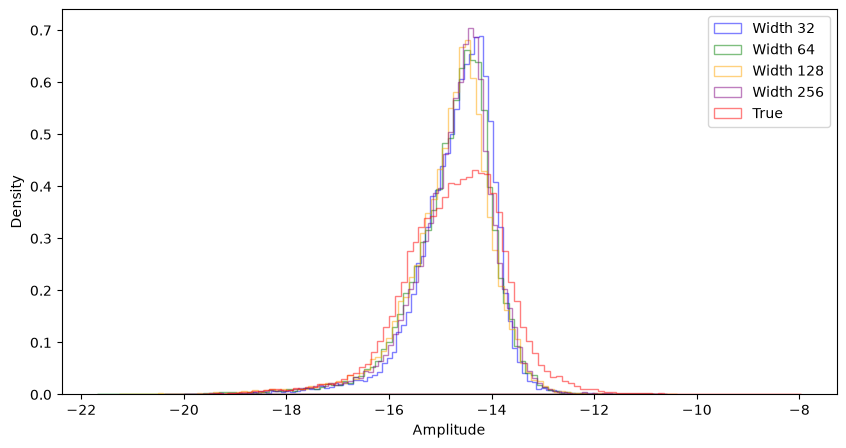

In [39]:
# Plotting the predicted vs true amplitudes for different depths
colors = ['blue', 'green', 'orange', 'purple']  # Define colors for each depth
plt.figure(figsize=(10, 5))
for width, predictions in predictions_dict.items():
    plt.hist(predictions, bins=100, alpha=0.5, label=f'Width {width}', density=True, histtype='stepfilled', fill=None, edgecolor=colors[widths.index(width)])
plt.hist(tst_amp_log_scaled, bins=100, alpha=0.5, label='True', density=True, histtype='stepfilled', fill=None, edgecolor='red')
plt.xlabel('Amplitude')
plt.ylabel('Density')
plt.legend()
plt.savefig('Plots/Widths_lipNN_test.pdf')
plt.show()

# Certification

Certification at inference is an important motivation of Lipschitz networks as they can quantify robustness of the models. For classification problems this is straight forward (given that one knows the norm being optimized for). For regression problems this is an open question, here we will try to use the certification methods provided by the classification tasks and instead give a margin of tolerable data drift.

For classification problems, the certification for a network optimized with the $l_2$ norm is defined as 
$$
r = \frac{m(x)}{L\sqrt{2}},
$$
where $m(x)$ is the margin of the prediction and $L$ is the Lipschitz constant. The margin is defined as the magnitude of the difference between the largest logit and the second largest logit.

FIGURE THIS OUT LATER